# LaptopDSS — Notebook tái lập, kiểm định và phản biện

**Mục tiêu.** Notebook này tái lập chuỗi bằng chứng của dự án LaptopDSS: đọc snapshot dữ liệu, kiểm tra chất lượng, mô tả EDA, chạy DSS AHP–TOPSIS, đọc kết quả ML, đo hiệu năng và ghi rõ giới hạn. Đây là tài liệu kỹ thuật phục vụ bảo vệ, không phải công cụ tạo số liệu mới.

> Lưu ý liêm chính: Dữ liệu là snapshot 513 listing (505 CellphoneS, 8 FPT Shop pilot). Kết quả không phải khảo sát người dùng, không phải khuyến nghị tài chính, và không chứng minh giá hiện tại còn hiệu lực.

## 1. Câu hỏi nghiên cứu và thiết kế đánh giá

1. Với một nhu cầu và các ràng buộc cứng, laptop nào gần phương án lý tưởng nhất theo AHP–TOPSIS?
2. Dữ liệu có đủ độ phủ để từng tiêu chí được đưa vào điểm không?
3. Mô hình hồi quy giá có vượt baseline không, và sai số còn lớn đến đâu?
4. Kết quả có ổn định khi thay đổi ngân sách/trọng số không?

**Tách vai trò:** TOPSIS tạo điểm phù hợp đa tiêu chí; ML định giá tham chiếu bằng OOF. Giao diện có thể ghép hậu xử lý 85% TOPSIS + 15% điểm ML, nhưng không đưa ML vào ma trận TOPSIS.

### Trước khi chạy: chuẩn bị môi trường phân tích

**Mục đích:** nạp các thư viện và xác định thư mục gốc của dự án. Ô này chưa phân tích laptop nào.

**Đầu ra cần đọc:** dòng `Project root: ...` xác nhận notebook đã tìm đúng thư mục chứa `data/` và `src/`. Nếu ô báo lỗi, hãy mở notebook từ project root hoặc thư mục `notebooks/`.

In [1]:
from pathlib import Path
import json, sys, time, statistics, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # tái lập được cả khi chạy không có giao diện
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)  # Thay bằng ghi chú tiếng Việt ở phần ML
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive.*')

ROOT = Path.cwd()
if not (ROOT / 'data' / 'catalog' / 'laptops.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'catalog' / 'laptops.csv').exists(), 'Mở notebook từ thư mục notebooks hoặc project root.'
sys.path.insert(0, str(ROOT / 'src'))
from dss_ranking import PRESETS, compute_ahp_weights, evaluate, analyze_weight_sensitivity

DATA = ROOT / 'data' / 'catalog' / 'laptops.csv'
ARTIFACTS = ROOT / 'data' / 'artifacts'
REPORTS = ROOT / 'data' / 'reports'
print(f'Thư mục gốc dự án: {ROOT}')

Thư mục gốc dự án: D:\Dự Án DSS 1


## 2. Nạp dữ liệu và kiểm tra tính toàn vẹn

Các kiểm tra này trả lời trực tiếp câu hỏi phản biện: số mẫu có đúng không, nguồn có cân bằng không, có khóa định danh/URL trùng không, và tiêu chí nào có thể chấm điểm theo ngưỡng D14 (độ phủ ≥80%).

### Nội dung ô code kế tiếp: kiểm tra catalog có đáng tin để phân tích không

**Ô này làm gì:** đọc `data/catalog/laptops.csv`, kiểm tra phải có đúng 513 listing, ID/URL không trùng, gồm 505 CellphoneS và 8 FPT Shop, đồng thời kiểm tra cân nặng có nằm trong khoảng hợp lý.

**Cách đọc kết quả:** bảng `source / listings` là số lượng laptop theo nguồn. Dòng `Integrity checks: PASS` nghĩa là dữ liệu đầu vào đạt các điều kiện kiểm tra cơ bản; không phải kết luận rằng mọi thông số đều đầy đủ.

In [2]:
df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert len(df) == 513, f'Expected 513 rows, found {len(df)}'
assert df['source_product_id'].is_unique
assert df['source_url'].is_unique
source_counts = df['source'].value_counts()
assert source_counts.get('cellphones', 0) == 505
assert source_counts.get('FPT Shop', 0) == 8
weights = pd.to_numeric(df['weight_kg'], errors='coerce')
assert weights.dropna().between(0.4, 5.0).all(), 'weight_kg outside plausible laptop range'
display(source_counts.rename_axis('source').reset_index(name='listings'))
print('Kiểm tra tính toàn vẹn: ĐẠT — 513 dòng; ID/URL không trùng; số lượng theo nguồn đã được xác nhận.')

Kiểm tra tính toàn vẹn: ĐẠT — 513 dòng; ID/URL không trùng; số lượng theo nguồn đã được xác nhận.


,source,listings
0,cellphones,505
1,FPT Shop,8


### Nội dung ô code kế tiếp: độ phủ thông tin của từng tiêu chí

**Ô này làm gì:** đếm bao nhiêu trong 513 laptop có giá, RAM, SSD, cân nặng, benchmark CPU, Hz màn hình, độ sáng và khe RAM. Theo quyết định D14, trường có độ phủ từ 80% mới được dùng để chấm điểm; thấp hơn chỉ nên hiển thị/lọc.

**Cách đọc kết quả:** cột `present` là số laptop có dữ liệu, `coverage_%` là tỷ lệ có dữ liệu, `D14_status` nói trường đó có đủ điều kiện vào thuật toán hay không. Dòng GPU Time Spy báo riêng độ phủ trên toàn bộ catalog và riêng nhóm có card đồ họa rời.

In [3]:
coverage_fields = ['sale_price_vnd','ram_gb','storage_total_gb','weight_kg','cpu_benchmark_multi_core','cpu_benchmark_single_core','refresh_rate_hz','brightness_nits','ram_slots']
coverage = pd.DataFrame({
    'field': coverage_fields,
    'present': [(df[c] != '').sum() for c in coverage_fields],
})
coverage['coverage_%'] = (coverage['present'] / len(df) * 100).round(1)
coverage['D14_status'] = np.where(coverage['coverage_%'] >= 80, 'eligible for scoring', 'display/filter only')
display(coverage)
# GPU Time Spy is meaningful only for discrete GPUs, so report both denominators.
dgpu = df[df['gpu_type'].eq('discrete')]
print(f"GPU Time Spy: {(df['gpu_benchmark_time_spy'] != '').sum()}/{len(df)} trên toàn catalog; {(dgpu['gpu_benchmark_time_spy'] != '').sum()}/{len(dgpu)} trong nhóm có GPU rời.")

GPU Time Spy: 163/513 trên toàn catalog; 163/164 trong nhóm có GPU rời.


,field,present,coverage_%,D14_status
0,sale_price_vnd,513,100.0,eligible for scoring
1,ram_gb,513,100.0,eligible for scoring
2,storage_total_gb,513,100.0,eligible for scoring
3,weight_kg,510,99.4,eligible for scoring
4,cpu_benchmark_multi_core,439,85.6,eligible for scoring
5,cpu_benchmark_single_core,439,85.6,eligible for scoring
6,refresh_rate_hz,430,83.8,eligible for scoring
7,brightness_nits,406,79.1,display/filter only
8,ram_slots,402,78.4,display/filter only


## 3. EDA tối thiểu nhưng tái lập

EDA mô tả snapshot, không suy luận dân số. Giá được hiển thị theo triệu VNĐ; biểu đồ giúp nhận diện lệch phải và lý do mô hình ML dự báo trên log(price).

### Nội dung ô code kế tiếp: mô tả phân bố giá

**Ô này làm gì:** tính các thống kê giá cơ bản và vẽ hai histogram: giá gốc theo triệu VNĐ và log(giá).

**Cách đọc kết quả:** bảng cho biết catalog tập trung ở phân khúc nào. Histogram log dùng để nhìn phân bố bớt lệch và giải thích vì sao mô hình ML học `log(price)`, không phải vì giá log là giá người dùng nhìn thấy.

,price_vnd
count,5.130000e+02
mean,3.726261e+07
std,2.247349e+07
min,8.790000e+06
25%,2.399000e+07
50%,2.959000e+07
75%,4.199000e+07
max,1.999900e+08


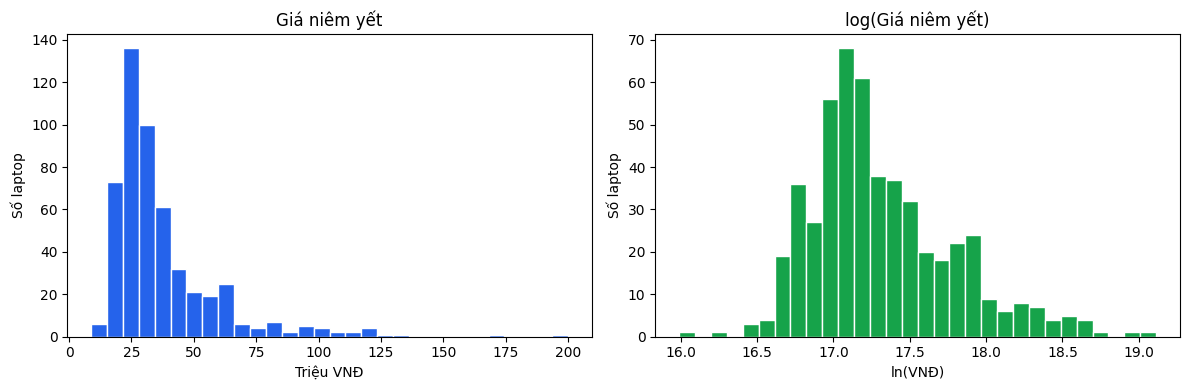

In [4]:
price = pd.to_numeric(df['sale_price_vnd'], errors='coerce')
summary = price.describe(percentiles=[.25, .5, .75]).to_frame('price_vnd')
display(summary)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(price / 1e6, bins=30, color='#2563eb', edgecolor='white')
ax[0].set(title='Giá niêm yết', xlabel='Triệu VNĐ', ylabel='Số laptop')
ax[1].hist(np.log(price), bins=30, color='#16a34a', edgecolor='white')
ax[1].set(title='log(Giá niêm yết)', xlabel='ln(VNĐ)', ylabel='Số laptop')
plt.tight_layout()
plt.show()

### 3.1. Bộ 5 biểu đồ EDA đã sinh sẵn

Năm biểu đồ dưới đây được `src/visualize_data.py` tạo tái lập từ catalog và artifact ML. Chúng được hiển thị trực tiếp trong notebook để người đọc không phải mở thư mục `data/reports/figures/` riêng.

- **Phân phối giá:** nhận biết catalog tập trung ở phân khúc nào.
- **Phân bố thương hiệu:** kiểm tra mức đại diện của từng hãng.
- **Giá và CPU:** quan sát mối liên hệ giữa hiệu năng CPU đa nhân với giá.
- **Độ phủ trường dữ liệu:** kiểm tra tiêu chí nào đủ dữ liệu cho DSS.
- **So sánh R² mô hình:** đặt mô hình ML triển khai trong tương quan với các baseline.


Biểu đồ 1 — Phân phối giá bán

Biểu đồ 2 — Phân bố thương hiệu

Biểu đồ 3 — Tương quan giá bán và CPU đa nhân

Biểu đồ 4 — Độ phủ dữ liệu theo trường

Biểu đồ 5 — So sánh R² các mô hình ML


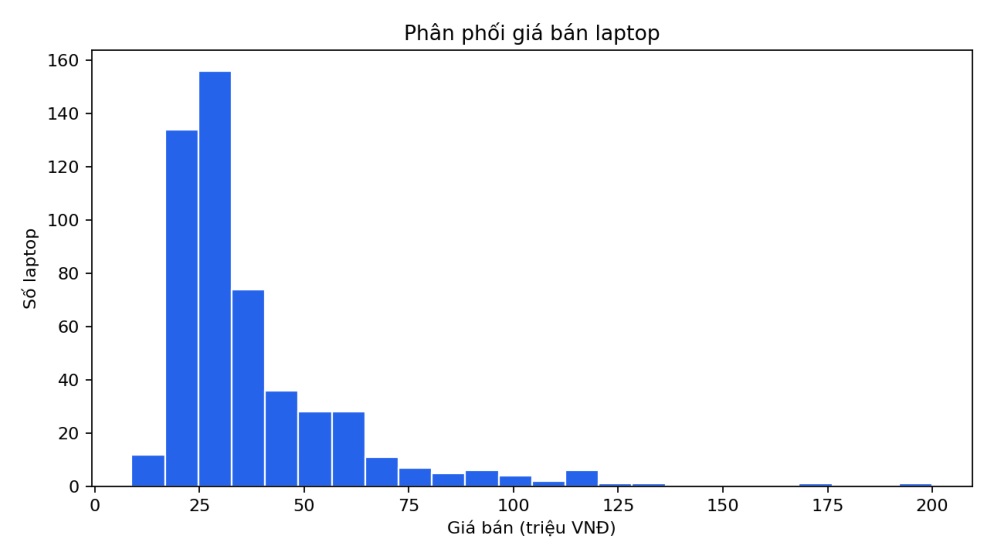

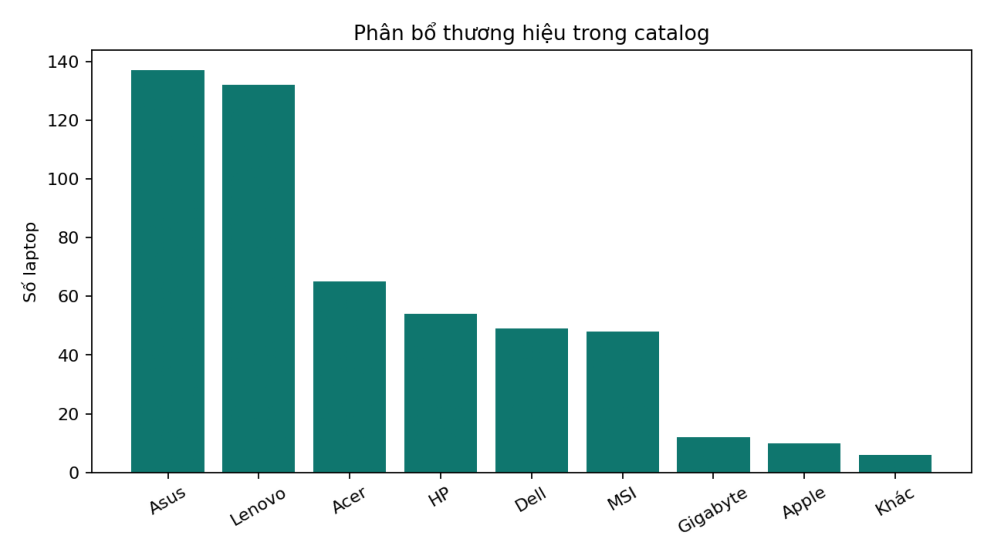

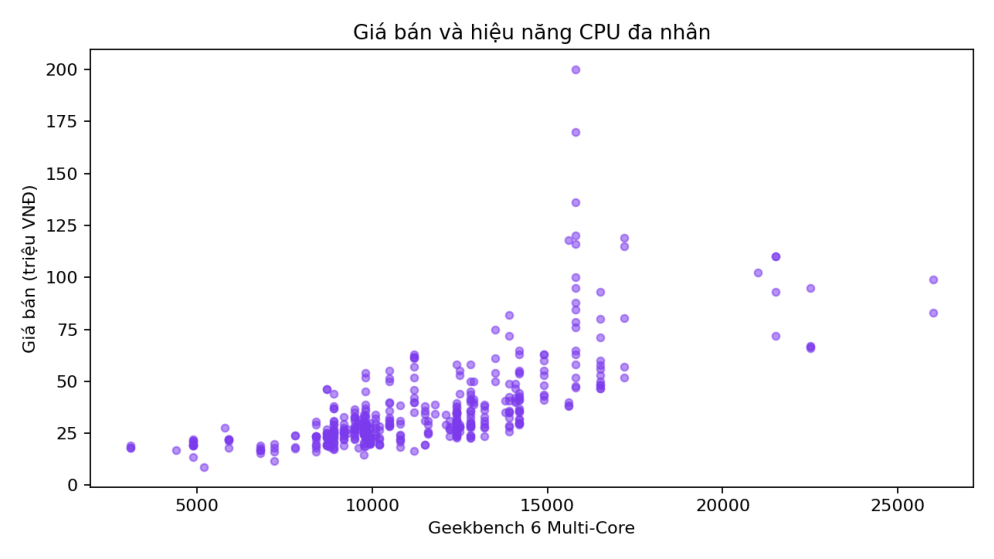

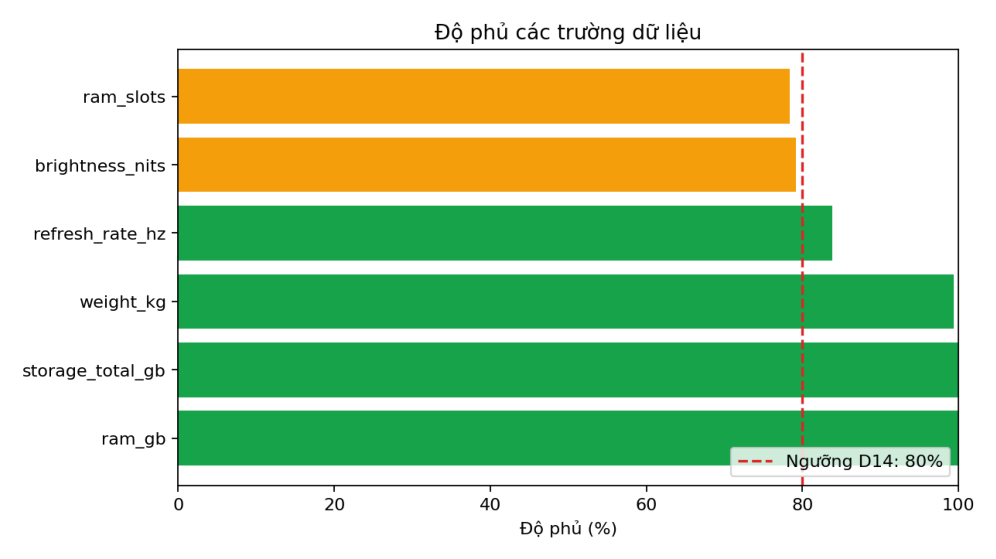

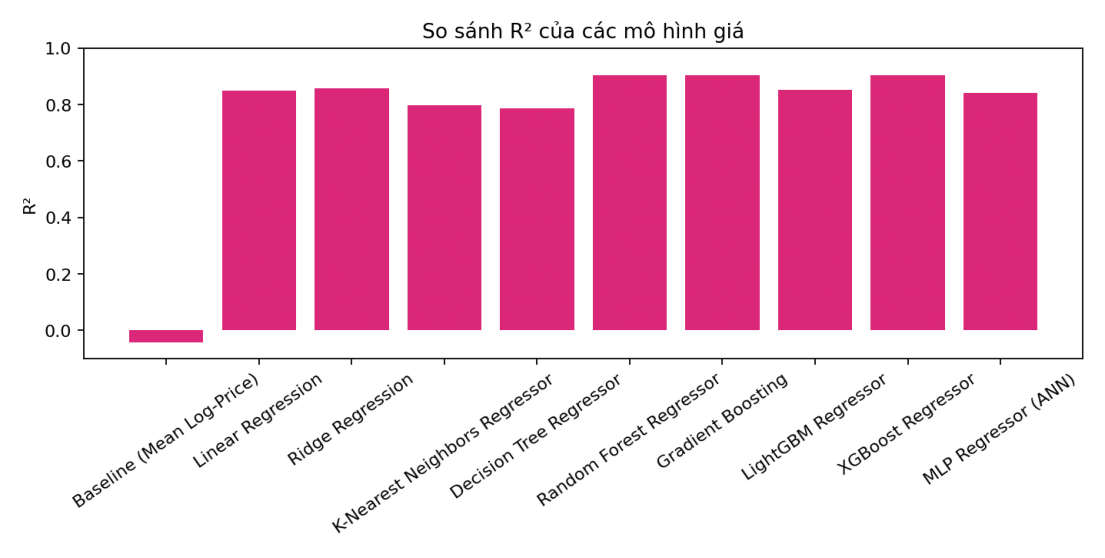

In [5]:
figures = [
    ('01_price_distribution.png', 'Biểu đồ 1 — Phân phối giá bán'),
    ('02_brand_distribution.png', 'Biểu đồ 2 — Phân bố thương hiệu'),
    ('03_price_vs_cpu.png', 'Biểu đồ 3 — Tương quan giá bán và CPU đa nhân'),
    ('04_field_coverage.png', 'Biểu đồ 4 — Độ phủ dữ liệu theo trường'),
    ('05_model_comparison_r2.png', 'Biểu đồ 5 — So sánh R² các mô hình ML'),
]
figures_dir = REPORTS / 'figures'
for filename, title in figures:
    path = figures_dir / filename
    print(f'\n{title}')
    if path.exists():
        image = plt.imread(path)
        fig, ax = plt.subplots(figsize=(14, 7))
        ax.imshow(image)
        ax.axis('off')
    else:
        print(f'Chưa có {filename}. Chạy: python -X utf8 -m src.visualize_data')

## 4. DSS: AHP, ràng buộc cứng và TOPSIS

Mỗi profile dùng ma trận so sánh cặp. Chỉ số nhất quán CR < 0.10 là điều kiện cần để ma trận được chấp nhận. Trước TOPSIS, chương trình lọc ràng buộc ngân sách/OS/RAM/SSD; Gaming luôn bắt buộc Windows, dGPU và 144Hz. Các giá trị thiếu của tiêu chí còn lại không bị gán 0: nếu coverage <80% tiêu chí bị loại, nếu ≥80% thì bản ghi thiếu bị loại rõ lý do.

### Nội dung ô code kế tiếp: kiểm tra trọng số AHP của 4 nhóm nhu cầu

**Ô này làm gì:** tính trọng số tiêu chí từ ma trận so sánh cặp của bốn hồ sơ: Sinh viên, Mỏng nhẹ, Kỹ thuật/Lập trình và Gaming.

**Cách đọc kết quả:** cột `weights` cho biết mức ưu tiên tương đối giữa các tiêu chí. `CR` là Consistency Ratio; mọi dòng phải nhỏ hơn 0.10, nghĩa là ma trận trọng số đủ nhất quán để sử dụng.

In [6]:
ahp_rows = []
for key in ['student_budget', 'slim_mobility', 'technical_coding', 'gaming']:
    weights, lambda_max, cr = compute_ahp_weights(PRESETS[key]['matrix'])
    assert cr < 0.10
    ahp_rows.append({'preset': key, 'lambda_max': round(lambda_max, 4), 'CR': round(cr, 4), 'weights': ', '.join(f'{w:.1%}' for w in weights)})
display(pd.DataFrame(ahp_rows))

,preset,lambda_max,CR,weights
0,student_budget,5.0331,0.0074,"40.2%, 24.5%, 13.7%, 13.7%, 7.9%"
1,slim_mobility,5.0735,0.0164,"42.5%, 25.3%, 15.0%, 9.9%, 7.2%"
2,technical_coding,5.0680,0.0152,"43.0%, 26.0%, 9.2%, 15.8%, 6.1%"
3,gaming,5.0680,0.0152,"41.7%, 26.3%, 16.0%, 9.7%, 6.2%"


### Nội dung ô code kế tiếp: ví dụ đề xuất laptop thực tế

**Đầu vào:** hồ sơ `technical_coding`, ngân sách tối đa 25 triệu, RAM từ 16 GB và SSD từ 512 GB. Ô này lọc điều kiện bắt buộc, rồi xếp máy còn lại bằng TOPSIS.

**Cách đọc kết quả:** bảng là 5 máy đứng đầu; `topsis_score` càng cao thì máy càng gần phương án lý tưởng của hồ sơ này. `Excluded` là số máy bị loại bởi ràng buộc, không phải lỗi dữ liệu.

In [7]:
records = df.to_dict('records')
case = evaluate(records, preset_key='technical_coding', max_budget_vnd=25_000_000, min_ram_gb=16, min_storage_gb=512)
assert case['status'] in {'success', 'single_candidate'}
top = pd.DataFrame(case['rankings'][:5])
display(top[['rank','product_name_raw','sale_price_vnd','ram_gb','storage_total_gb','cpu_benchmark_multi_core','topsis_score']])
print('Tiêu chí đang tính điểm:', case['active_criteria'])
print('Số máy bị loại:', len(case['excluded']), '| Tiêu chí không dùng:', case['dropped_criteria'])

Tiêu chí đang tính điểm: [('cpu_benchmark_multi_core', 'benefit', 0.4301060407055067), ('ram_gb', 'fit', 0.2595335693030299), ('sale_price_vnd', 'cost', 0.09186266458857813), ('storage_total_gb', 'fit', 0.15789096908823247), ('weight_kg', 'cost', 0.060606756314652926)]
Số máy bị loại: 411 | Tiêu chí không dùng: []


,rank,product_name_raw,sale_price_vnd,ram_gb,storage_total_gb,cpu_benchmark_multi_core,topsis_score
0,1,Laptop Lenovo ThinkPad E14 Gen 7 21T90022VA,23990000,16,1024,12800.0,0.8484
1,2,Laptop ASUS VivoBook 14 M1407GA-LY270W,23690000,16,512,13200.0,0.8449
2,3,Laptop Lenovo ThinkBook 14 G8 IRL 21SG007TVN,22990000,16,512,12800.0,0.8390
3,4,Laptop Lenovo ThinkBook 16 G8 IRL 21SH0099VN,22990000,16,512,12800.0,0.8339
4,5,Laptop Lenovo ThinkPad E14 Gen 7 21T90021VA,23990000,16,512,12800.0,0.8332


## 5. Kiểm thử phản biện DSS

Đây không phải đánh giá “người dùng hài lòng”; đây là các assert bảo vệ các hứa hẹn thuật toán. Tình huống Gaming dưới đây là regression test cho lỗi trước đây: máy 60Hz hoặc thiếu Hz không được lọt vào danh sách Gaming ngay cả khi caller quên truyền filter UI.

### Nội dung ô code kế tiếp: phản biện kết quả DSS

**Ô này làm gì:** kiểm tra hồ sơ Gaming chỉ giữ laptop Windows, GPU rời và màn hình từ 144 Hz. Sau đó chạy OAT sensitivity: thay đổi từng trọng số để xem Top-1 có ổn định không.

**Cách đọc kết quả:** `PASS` xác nhận ràng buộc Gaming đã được áp dụng. `OAT Top-1 stability` cao nghĩa là Top-1 ít thay đổi trong các nhiễu động đã thử; không chứng minh trọng số đúng với mọi người dùng.

In [8]:
gaming = evaluate(records, preset_key='gaming', max_budget_vnd=50_000_000)
assert all(float(x['refresh_rate_hz']) >= 144 for x in gaming['rankings'])
assert all(x['os_name'] == 'Windows' and x['gpu_type'] == 'discrete' for x in gaming['rankings'])
print(f"Kiểm tra ràng buộc Gaming: ĐẠT — {len(gaming['rankings'])} laptop được xếp hạng đều dùng Windows + GPU rời + màn hình từ 144 Hz.")

sensitivity = analyze_weight_sensitivity(records, preset_key='technical_coding', max_budget_vnd=25_000_000)
print('Độ ổn định Top-1 theo OAT (%):', sensitivity['stability_rate_percent'])
print('Diễn giải: tỷ lệ cao nghĩa là Top-1 hiện tại ít thay đổi khi lần lượt điều chỉnh từng trọng số; không chứng minh trọng số đúng với mọi người dùng.')

Kiểm tra ràng buộc Gaming: ĐẠT — 98 laptop được xếp hạng đều dùng Windows + GPU rời + màn hình từ 144 Hz.
Độ ổn định Top-1 theo OAT (%): 90.0
Diễn giải: tỷ lệ cao nghĩa là Top-1 hiện tại ít thay đổi khi lần lượt điều chỉnh từng trọng số; không chứng minh trọng số đúng với mọi người dùng.


## 6. ML định giá: benchmark tái lập và artifact triển khai

Cell sau huấn luyện lại **5 mô hình bắt buộc của đề bài** (Linear Regression, KNN, Decision Tree, Random Forest, ANN) bằng Nested GroupKFold 5 outer folds / 3 inner folds. Kết quả chỉ hiển thị trong notebook, **không ghi đè artifact demo**. Sau đó notebook đọc artifact triển khai đã khóa để đối chiếu. So sánh dùng MAE/MAPE/R² cùng baseline; không chỉ nêu R².

**Lưu ý trung thực về ANN:** với mẫu snapshot nhỏ và không đồng nhất này, một số inner fold của bộ tối ưu L-BFGS có thể chạm giới hạn vòng lặp (`ConvergenceWarning`). Chỉ số ANN vẫn được ghi rõ để đối chiếu, nhưng ANN **không phải mô hình triển khai**; mô hình triển khai là Gradient Boosting được chọn theo Nested GroupKFold. Warning không bị ẩn và không được diễn giải là ANN đã hội tụ hoàn toàn.

### Nội dung ô code kế tiếp: kiểm chứng mô hình dự báo giá

**Ô này làm gì:** chạy lại đánh giá chéo cho các model so sánh, rồi đọc artifact ML đã lưu để hiển thị benchmark và model triển khai.

**Cách đọc kết quả:** `r2_mean` càng gần 1 càng tốt; `mae_mean` và `mape_mean` càng thấp càng tốt. Các chỉ số đánh giá độ chính xác, không khẳng định giá dự báo là giá thị trường chắc chắn.

In [9]:
from ml_price_prediction import assemble_feature_matrix, evaluate_models_nested_groupkfold, load_dataset

CORE_MODELS = ['Linear Regression', 'K-Nearest Neighbors Regressor', 'Decision Tree Regressor', 'Random Forest Regressor', 'MLP Regressor (ANN)']
ml_records, brands = load_dataset()
X_ml, y_ml, y_log_ml, groups_ml, _ = assemble_feature_matrix(ml_records, brands)
fresh_cv, _, _ = evaluate_models_nested_groupkfold(X_ml, y_ml, y_log_ml, groups_ml, model_names=CORE_MODELS)
fresh_table = pd.DataFrame(fresh_cv).T.rename_axis('model').reset_index()
display(fresh_table[['model', 'r2_mean', 'mae_mean', 'rmse_mean', 'mape_mean']].round({'r2_mean': 4, 'mae_mean': 0, 'rmse_mean': 0, 'mape_mean': 2}))
print('Lưu ý ANN: Một số lần huấn luyện nội bộ chạm giới hạn lặp của L-BFGS. ANN chỉ dùng để so sánh, không phải mô hình đang triển khai.')

metrics = json.loads((ARTIFACTS / 'price_model_metrics.json').read_text(encoding='utf-8'))
print('Mô hình đang triển khai:', metrics['best_model'])
print('Số mẫu:', metrics['dataset_size'], '| Số đặc trưng:', metrics['features_count'], '| sigma(log-price):', metrics['sigma_pred_log'])
model_table = pd.DataFrame(metrics['models_cv']).T.rename_axis('model').reset_index()
display(model_table[['model', 'r2_mean', 'mae_mean', 'rmse_mean', 'mape_mean']].round({'r2_mean': 4, 'mae_mean': 0, 'rmse_mean': 0, 'mape_mean': 2}))
print('Lưu ý khi trình bày: ML chỉ định giá tham chiếu. Khi bật trên giao diện, ML đóng góp tối đa 15% sau TOPSIS; MAE khoảng 4,6 triệu VNĐ nên từng dự báo riêng lẻ vẫn có độ bất định.')


ĐÁNH GIÁ NESTED GROUPKFOLD (5 FOLD NGOÀI, 3 FOLD TRONG ĐỂ TINH CHỈNH)
[Linear Regression               ] R2: +0.8500 ± 0.0287 | MAE:   5,378,828 ±   505,338 VND | MAPE: 14.34%
[K-Nearest Neighbors Regressor   ] R2: +0.7977 ± 0.0320 | MAE:   5,822,125 ±   353,013 VND | MAPE: 14.56%
[Decision Tree Regressor         ] R2: +0.7861 ± 0.0581 | MAE:   6,176,099 ±   881,255 VND | MAPE: 15.82%
[Random Forest Regressor         ] R2: +0.9023 ± 0.0199 | MAE:   4,599,702 ±   604,240 VND | MAPE: 12.35%
[MLP Regressor (ANN)             ] R2: +0.8406 ± 0.0183 | MAE:   5,696,267 ±   663,446 VND | MAPE: 14.90%
Lưu ý ANN: Một số lần huấn luyện nội bộ chạm giới hạn lặp của L-BFGS. ANN chỉ dùng để so sánh, không phải mô hình đang triển khai.
Mô hình đang triển khai: Gradient Boosting
Số mẫu: 513 | Số đặc trưng: 26 | sigma(log-price): 0.1617
Lưu ý khi trình bày: ML chỉ định giá tham chiếu. Khi bật trên giao diện, ML đóng góp tối đa 15% sau TOPSIS; MAE khoảng 4,6 triệu VNĐ nên từng dự báo riêng lẻ vẫn có độ

,model,r2_mean,mae_mean,rmse_mean,mape_mean
0,Linear Regression,0.84999,5378827.736781,8592556.438637,14.343752
1,K-Nearest Neighbors Regressor,0.797727,5822125.256462,9979641.820732,14.555016
2,Decision Tree Regressor,0.786147,6176098.97481,10294868.109344,15.818967
3,Random Forest Regressor,0.902306,4599701.530524,6982101.633599,12.350394
4,MLP Regressor (ANN),0.840578,5696267.319073,8905803.260782,14.900964


,model,r2_mean,mae_mean,rmse_mean,mape_mean
0,Baseline (Mean Log-Price),-0.041739,14174184.116744,22768807.547009,36.391469
1,Linear Regression,0.84999,5378827.736781,8592556.438637,14.343752
2,Ridge Regression,0.856785,5324051.775205,8405408.733773,14.250222
3,K-Nearest Neighbors Regressor,0.797727,5822125.256462,9979641.820732,14.555016
4,Decision Tree Regressor,0.786147,6176098.97481,10294868.109344,15.818967
5,Random Forest Regressor,0.902306,4599701.530524,6982101.633599,12.350394
6,Gradient Boosting,0.903433,4544509.704018,6935911.401339,12.235344
7,LightGBM Regressor,0.852057,4877960.890443,8498843.08747,12.482339
8,XGBoost Regressor,0.902306,4357566.529583,6934194.136752,11.925199
9,MLP Regressor (ANN),0.840578,5696267.319073,8905803.260782,14.900964


### 6.1. Chạy model đã train trên một cấu hình mới

Cell này dùng artifact Gradient Boosting đã khóa để định giá một cấu hình nhập tay, không lấy lại giá của một dòng catalog. Đây là cùng luồng với form **Định giá cấu hình mới** trên giao diện và endpoint `/api/predict_price`.

### Nội dung ô code kế tiếp: định giá thử một cấu hình mới

**Đầu vào:** laptop Asus, CPU benchmark 12.000/2.500, GPU rời 6 GB VRAM, RAM 16 GB, SSD 512 GB, 144 Hz, pin 60 Wh, nặng 2,2 kg và giá đang bán 20 triệu.

**Cách đọc kết quả:** `gia_du_bao_vnd` là giá tham chiếu từ model; hai cận 95% thể hiện độ bất định; phần trăm chênh lệch so sánh giá nhập với giá tham chiếu. Đây không phải cam kết giá thị trường hay lời khuyên chắc chắn phải mua.

In [10]:
from api import PredictPriceRequest, build_prediction_vector, get_model_pipeline

new_config = PredictPriceRequest(
    cpu_benchmark_multi=12000, cpu_benchmark_single=2500,
    gpu_benchmark_time_spy=6000, is_discrete_gpu=True, gpu_vram_gb=6,
    ram_gb=16, storage_total_gb=512, refresh_rate_hz=144,
    brightness_nits=300, battery_capacity_wh=60, weight_kg=2.2,
    brand='Asus', observed_price_vnd=20_000_000,
)
pipeline = get_model_pipeline(ARTIFACTS / 'price_model.joblib')
raw_vector = build_prediction_vector(new_config, pipeline['feature_names'])
scaled_vector = pipeline['scaler'].transform(raw_vector)
imputed_vector = pipeline['imputer'].transform(scaled_vector)
pred_log = float(pipeline['model'].predict(imputed_vector)[0])
predicted_vnd = float(np.exp(pred_log))
sigma = float(pipeline['sigma_pred'])
lower_vnd, upper_vnd = np.exp(pred_log - 1.96 * sigma), np.exp(pred_log + 1.96 * sigma)
gap_pct = (predicted_vnd - new_config.observed_price_vnd) / predicted_vnd * 100
display(pd.DataFrame([{
    'model': pipeline['model_name'], 'gia_dang_ban_vnd': new_config.observed_price_vnd,
    'gia_du_bao_vnd': round(predicted_vnd, -4), 'can_du_bao_95_vnd': round(lower_vnd, -4),
    'can_tren_du_bao_95_vnd': round(upper_vnd, -4), 'chenh_lech_voi_tham_chieu_pct': round(gap_pct, 2),
}]))
print('Đây là dự báo tham chiếu từ model, không phải cam kết giá thị trường hoặc khuyến nghị mua.')

Đây là dự báo tham chiếu từ model, không phải cam kết giá thị trường hoặc khuyến nghị mua.


,model,gia_dang_ban_vnd,gia_du_bao_vnd,can_du_bao_95_vnd,can_tren_du_bao_95_vnd,chenh_lech_voi_tham_chieu_pct
0,Gradient Boosting,20000000.0,34940000.0,25450000.0,47970000.0,42.76


## 7. Đo hiệu năng tái lập

Đo 100 lần in-memory trên cùng catalog, không tính thời gian khởi động Python, đọc file, mạng hay trình duyệt. Đây là benchmark engine đơn luồng tại máy chạy notebook; không được diễn giải như tải production/concurrent users.

### Nội dung ô code kế tiếp: đo tốc độ xếp hạng

**Ô này làm gì:** chạy cùng một truy vấn TOPSIS 100 lần và đo thời gian thực thi.

**Cách đọc kết quả:** `mean_ms`, `median_ms` và `p95_ms` lần lượt là trung bình, trung vị và mức thời gian mà 95% lần chạy không vượt quá. Đây là benchmark cục bộ trên máy đang chạy notebook, không phải cam kết hiệu năng cho mọi máy chủ.

In [11]:
timings_ms = []
for _ in range(100):
    t0 = time.perf_counter()
    evaluate(records, preset_key='technical_coding', max_budget_vnd=35_000_000)
    timings_ms.append((time.perf_counter() - t0) * 1_000)
bench = {'runs': len(timings_ms), 'mean_ms': statistics.mean(timings_ms), 'median_ms': statistics.median(timings_ms), 'p95_ms': np.percentile(timings_ms, 95), 'max_ms': max(timings_ms)}
display(pd.DataFrame([bench]).round(2))

,runs,mean_ms,median_ms,p95_ms,max_ms
0,100,3.91,3.18,3.7,70.86


## 8. Kết luận, giới hạn và câu trả lời bảo vệ

**Đã chứng minh:** engine tái lập trên snapshot, các ràng buộc cứng và độ phủ được kiểm tra, CR đạt ngưỡng, ML vượt baseline nội bộ, và latency in-memory thấp cho quy mô 513 bản ghi. Snapshot có trường `collected_at` cho mọi listing (17/10/2026).

**Chưa được chứng minh:** độ hài lòng người dùng, độ chính xác giá theo thời gian, tổng quát hóa tới retailer thứ ba, hiệu năng đa người dùng, hay ưu thế thống kê chắc chắn giữa Gradient Boosting và XGBoost. Mặc dù có `collected_at`, mỗi listing chỉ có một quan sát giá nên không thể làm temporal validation. FPT có 8 mẫu trong catalog; sau khi loại 1 cấu hình trùng train/test, holdout còn 7 mẫu nên không được gọi là external validation mạnh.

**Nếu bị hỏi KNN/Decision Tree/ANN:** pipeline có KNN Regressor, Decision Tree Regressor và MLP/ANN thật để so sánh, ngoài KNNImputer dùng trong tiền xử lý. Chúng không được triển khai vì Gradient Boosting dẫn đầu theo $R^2$ của Nested GroupKFold trong artifact hiện hành.